# Predictive Regulated Search — problemi di matto in N mosse

**Problema.** Data una posizione "il tratto muove e dà matto in N" (N = 1, 2, 3), scegliere la **prima mossa**.
La decisione si ottiene con una ricerca AND/OR a budget: nodi OR = attaccante (basta una mossa), nodi AND = difensore (vanno confutate tutte le difese).

| Sistema | Ordinamento | Allocazione del calcolo |
|---|---|---|
| **A** baseline | euristica classica: scacchi → catture MVV-LVA → resto | depth-first uniforme |
| **B** predittivo | predittore appreso $\hat P_\theta(s,a)$ | depth-first uniforme (come A) |
| **C** predittivo + regolato | come B | **regolatore** alla radice: ampiezza, quote di budget, stop |

Budget online = numero di **espansioni** (generazioni di mosse legali). Il calcolo dell'insegnante e del training è offline e separato.

Struttura del progetto: `src/` (codice), `data/` (puzzle e coppie etichettate), `models/`, `results/`, `figures/`, `tests/`.
Il notebook usa i risultati già calcolati; per rigenerare tutto mettere a `True` i flag qui sotto (tempi su 2 core).

In [1]:
import os, sys, json, pickle, subprocess
ROOT = os.path.abspath('.')
SRC = os.path.join(ROOT, 'src')
sys.path.insert(0, SRC)
os.environ.setdefault('OMP_NUM_THREADS', '1')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

RECOMPUTE_DATA  = False   # ~20 min: genera e certifica i puzzle (Step 1)
RECOMPUTE_MODEL = False   # ~4 min : etichette dell'insegnante + training (Step 3-4)
RECOMPUTE_TUNING = False  # ~2 min : taratura del regolatore su validation (Step 7)
RECOMPUTE_BENCH = False   # ~15 min: benchmark sul test + tempo reale (Step 8-9)

def run(script, *args):
    r = subprocess.run([sys.executable, script, *args], cwd=SRC, capture_output=True, text=True)
    print(r.stdout[-3000:], r.stderr[-2000:])
    r.check_returncode()

from minichess import Board
from analysis import (load_runs, load_info, summary, paired_gain, efficiency, plot_solve_curves,
                      residual_analysis, stop_danger, style_ax, COL, SYSTEM_LABEL, INK2)
print('ok')

ok


## Step 0 — Motore scacchistico e correttezza

L'ambiente di sviluppo non permetteva di installare `python-chess`, quindi `src/minichess.py` implementa da zero la generazione delle mosse legali (arrocco, en passant, promozioni, inchiodature, scacchi doppi).
È validato con i conteggi *perft* di riferimento su 6 posizioni standard. Il secondo test verifica che il sistema A, con budget illimitato, dimostri la mossa corretta su tutti i puzzle provati.

In [2]:
run(os.path.join('..', 'tests', 'test_perft.py'))
run(os.path.join('..', 'tests', 'test_search.py'))

ok   depth 1:      20 (expected      20)  rnbqkbnr/pppppppp/8/8/8/8/PPPPPPPP/RNBQK
ok   depth 2:     400 (expected     400)  rnbqkbnr/pppppppp/8/8/8/8/PPPPPPPP/RNBQK
ok   depth 3:    8902 (expected    8902)  rnbqkbnr/pppppppp/8/8/8/8/PPPPPPPP/RNBQK
ok   depth 4:  197281 (expected  197281)  rnbqkbnr/pppppppp/8/8/8/8/PPPPPPPP/RNBQK
ok   depth 1:      48 (expected      48)  r3k2r/p1ppqpb1/bn2pnp1/3PN3/1p2P3/2N2Q1p
ok   depth 2:    2039 (expected    2039)  r3k2r/p1ppqpb1/bn2pnp1/3PN3/1p2P3/2N2Q1p
ok   depth 3:   97862 (expected   97862)  r3k2r/p1ppqpb1/bn2pnp1/3PN3/1p2P3/2N2Q1p
ok   depth 1:      14 (expected      14)  8/2p5/3p4/KP5r/1R3p1k/8/4P1P1/8 w - - 0 
ok   depth 2:     191 (expected     191)  8/2p5/3p4/KP5r/1R3p1k/8/4P1P1/8 w - - 0 
ok   depth 3:    2812 (expected    2812)  8/2p5/3p4/KP5r/1R3p1k/8/4P1P1/8 w - - 0 
ok   depth 4:   43238 (expected   43238)  8/2p5/3p4/KP5r/1R3p1k/8/4P1P1/8 w - - 0 
ok   depth 1:       6 (expected       6)  r3k2r/Pppp1ppp/1b3nbN/nP6/BBP1P3/q4N2/Pp
ok  

## Step 1 — Dati

Il dataset principale è estratto direttamente dal database aperto di Lichess (`https://database.lichess.org/lichess_db_puzzle.csv.zst`) e certificato tramite il `Teacher` esaustivo (`src/build_lichess_dataset.py`):
posizioni umane reali da partite giocate, con rating Elo, URL Lichess e PuzzleId, tenute solo se il solver esaustivo certifica:

- matto in **esattamente** N mosse;
- **1–2 prime mosse vincenti**, cioè una decisione reale.

L'insieme di **tutte** le prime mosse vincenti è salvato: è la verità indipendente usata per valutare le decisioni.

Split: N=1,2 → train/val/test; N=3 → **solo test** (shift di distribuzione).
Un set extra di 600 matti in 3 (sempre dal database Lichess) serve per l'ablation 4b e per tarare il regolatore.
Lo split è riproducibile (`data/split.json`) e garantisce insiemi di test disgiunti da training e validazione.

In [3]:
if RECOMPUTE_DATA:
    run('build_lichess_dataset.py', '--n1', '2500', '--n2', '2500', '--n3', '500', '--n3_extra', '600')
from experiment import load_puzzles
P = pd.DataFrame(load_puzzles())
split = json.load(open('data/split.json'))
where = {i: s for s, ids in split.items() for i in ids}
P['split'] = P.id.map(where)
P['cls'] = np.where(P.sacrifice, 'sacrifice', np.where(P.quiet, 'quiet', 'check/capture'))
tab = P.groupby('n').agg(puzzles=('id', 'size'), key_check=('check', 'mean'), key_capture=('capture', 'mean'),
                         key_quiet=('quiet', 'mean'), key_sacrifice=('sacrifice', 'mean'),
                         two_keys=('keys', lambda k: np.mean([len(x) == 2 for x in k])), legal_moves=('n_legal', 'mean'))
print(P.groupby(['split', 'n']).size().unstack(fill_value=0))
tab.round(3)

n         1     2    3
split                 
test    400   400  500
train  1900  1900    0
val     200   200    0


,puzzles,key_check,key_capture,key_quiet,key_sacrifice,two_keys,legal_moves
n,,,,,,,
1,2500,1.000,0.422,0.000,0.564,0.032,34.889
2,2500,0.990,0.275,0.009,0.443,0.000,32.744
3,500,0.972,0.384,0.022,0.620,0.000,33.062


k7/P7/1K6/1N6/2n5/4p1p1/8/8 w - - 2 60


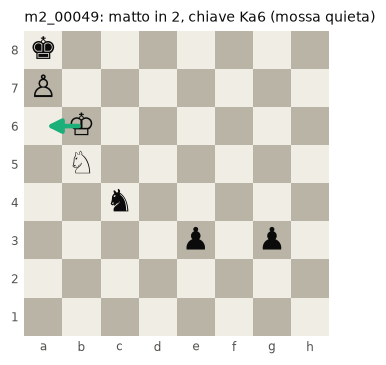

In [4]:
from viz import draw_board
ex = P[(P.n == 2) & P.quiet].iloc[0]
fig, ax = plt.subplots(figsize=(3.6, 3.6))
draw_board(ax, ex.fen, arrow=ex['keys'][0], title=f"{ex.id}: matto in 2, chiave {ex.key_san} (mossa quieta)")
print(ex.fen)

## Step 2 — Ricerca: stato, espansione, orizzonte, frontiera attiva (`src/search.py`)

- **Oggetto della ricerca**: l'albero AND/OR delle continuazioni per ≤ 2N−1 semimosse a partire dalla posizione del puzzle; la decisione è la mossa alla radice.
- **Stato**: (posizione, *d*), con *d* = semimosse ancora a disposizione dell'attaccante.
- **Espansione**: una generazione di mosse legali di un nodo. È l'unità di budget.
- **Orizzonte**: le foglie dell'albero esplicito, cioè nodi generati ma non espansi, più le foglie di profondità (*d* esaurito: lì la ricerca esplicita si ferma).
- **Frontiera attiva**: la parte dell'orizzonte ancora idonea a ricevere calcolo. Ne sono esclusi i nodi sotto un nodo già risolto (PROVEN/DISPROVEN) e, in C, i nodi sotto mosse radice *rinviate* dal regolatore.

Cosa succede alle alternative che escono dalla frontiera attiva:

1. **risolte**: il loro esito è certo, perché il solver è corretto;
2. **tagliate**: sono fratelli di un nodo che ha già deciso il padre, quindi irrilevanti;
3. **rinviate** (solo C): non sono risolte, e la loro probabilità resta nel residuo ρ.

Qui sotto: un matto in 3 con budget 200. Per ogni sistema si vede dove è andato il calcolo e com'è fatta la frontiera allo stop.

In [5]:
from model import Predictor, root_candidates
from search import Searcher, HeuristicPolicy, ModelPolicy, frontier_stats, root_allocation, softmax_logits
from regulator import solve_regulated
from run_all import config
params, extra = config()
pred = Predictor(pickle.load(open('models/gbm.pkl', 'rb')))
pz = load_puzzles('test'); pz = {p['id']: p for p in pz}
p = pz['m3_00158']
rows = []
alloc = {}
for name in 'ABC':
    pred.clear(); b = Board(p['fen'])
    s = Searcher(HeuristicPolicy() if name == 'A' else ModelPolicy(pred), 200)
    m, proven = s.solve(b, 3) if name != 'C' else solve_regulated(s, b, 3, pred, params)
    alloc[name] = {b.uci(k): v for k, v in root_allocation(s).items() if v > 0}
    rows.append({'system': name, 'move': b.uci(m), 'correct': b.uci(m) in p['keys'], 'proven': proven, 'used': s.used, **frontier_stats(s)})
print('chiave:', p['keys'], '| mosse legali:', p['n_legal'])
display_df = pd.DataFrame(rows); print(display_df.to_string(index=False))
print('\nespansioni spese sotto ogni mossa radice:')
for k, v in alloc.items(): print(k, dict(sorted(v.items(), key=lambda x: -x[1])[:6]))

chiave: ['d6c7'] | mosse legali: 29
system move  correct  proven  used  expanded  horizon  active  closed  deferred
     A d6c7     True    True   190       190     2672       0    2672         0
     B d6c7     True    True   151       151     1172       0    1172         0
     C d6c7     True    True    87        87      705       0     705         0

espansioni spese sotto ogni mossa radice:
A {'d6d7': 32, 'd6f6': 32, 'd6b6': 32, 'd6e7': 32, 'd6f8': 32, 'd6c7': 29}
B {'d6b8': 106, 'd6e7': 39, 'd6c7': 5}
C {'d6b8': 53, 'd6e7': 28, 'd6c7': 5}


## Step 3–4 — Target dall'insegnante e predittore $\hat P_\theta$ (`src/teacher.py`, `src/model.py`)

**Cosa si predice.** $\hat P_\theta(s,a)$ = probabilità che, dopo la mossa *a*, l'attaccante abbia ancora un matto forzato entro le semimosse rimaste.

- Nei nodi OR significa "*a* inizia il matto": si esplorano prima i valori alti.
- Nei nodi AND significa "la risposta *b* non salva il difensore": si esplorano prima i valori bassi (la fuga più probabile), per confutare presto.

**Target.** Il solver esaustivo senza budget etichetta **tutte** le mosse di:

- la radice;
- i nodi AND dopo la chiave e dopo 2 mosse sbagliate "difficili" (scacchi o catture);
- alcuni nodi OR interni.

Il predittore vede così la stessa distribuzione di nodi che incontra in ricerca.

**Modello.** Gradient boosting (sklearn `HistGradientBoostingClassifier`, LightGBM non installabile) su 28 feature nel riferimento "re da mattare": scacco, cattura, pezzo, case di fuga prima/dopo, zona del re attaccata, pezzo in presa (sacrificio), distanza dal re, materiale, ecc. Le feature richiedono solo make/unmake e test di attacco, **mai** una generazione di mosse del figlio: per questo non contano come espansioni, esattamente come il test di scacco usato dall'euristica di A. Ablation: regressione logistica sulle stesse feature.

In [6]:
if RECOMPUTE_MODEL:
    run('train.py'); run('train_shift.py')
stats = json.load(open('results/dataset_stats.json')); M = json.load(open('results/predictor_metrics.json'))
print('coppie di training:', stats['train']['pairs'], '| per tipo di nodo:', stats['train']['by_type'],
      '| positivi:', round(stats['train']['pos_rate'], 3), '| tempo etichettatura:', round(stats['label_time_s']), 's')
rows = []
for mdl in ('gbm', 'logreg'):
    for sp in ('val', 'test_n12', 'test_n3'):
        for typ, v in M[mdl][sp].items():
            rows.append({'model': mdl, 'split': sp, 'node': typ, **{k: v[k] for k in ('auc', 'logloss', 'ece', 'n')}})
pd.DataFrame(rows).pivot_table(index=['split', 'node'], columns='model', values=['auc', 'ece']).round(3)

coppie di training: 151175 | per tipo di nodo: {'and': 73431, 'or_int': 10531, 'root': 67213} | positivi: 0.107 | tempo etichettatura: 178 s


auc           ece       
model              gbm logreg    gbm logreg
split    node                              
test_n12 all     0.930  0.892  0.015  0.018
         and     0.791  0.746  0.031  0.023
         or_int  0.992  0.958  0.018  0.124
         root    0.997  0.990  0.003  0.014
test_n3  all     0.909  0.923  0.053  0.045
         and     0.704  0.703  0.192  0.129
         or_int  0.992  0.989  0.007  0.011
         root    0.990  0.976  0.005  0.025
val      all     0.948  0.913  0.013  0.020
         and     0.838  0.788  0.024  0.022
         or_int  0.991  0.954  0.013  0.113
         root    0.998  0.990  0.003  0.017

In [7]:
rows = []
for mdl in ('gbm', 'logreg'):
    for sp, v in M[mdl]['root_decision'].items():
        rows.append({'model': mdl, 'split': sp, **v})
print('Accuratezza della sola predizione alla radice (argmax P̂ = mossa vincente), T calibrata:',
      {m: M[m]['T'] for m in ('gbm', 'logreg')})
pd.DataFrame(rows).set_index(['model', 'split']).round(3)

Accuratezza della sola predizione alla radice (argmax P̂ = mossa vincente), T calibrata: {'gbm': 1.0, 'logreg': 0.7}


top1   top3  median_rank  mean_rank    n
model  split                                             
gbm    val      0.928  1.000          1.0      1.082  400
       test_n1  0.968  0.998          1.0      1.040  400
       test_n2  0.898  0.995          1.0      1.132  400
       test_n3  0.782  0.970          1.0      1.354  500
logreg val      0.860  0.988          1.0      1.220  400
       test_n1  0.948  0.998          1.0      1.068  400
       test_n2  0.772  0.982          1.0      1.332  400
       test_n3  0.620  0.920          1.0      1.802  500

Feature più influenti (coefficienti logreg standardizzati):
is_attacker_move    -3.26
gives_check          2.71
dk_escapes_after    -0.62
d_after              0.48
dk_escapes_delta    -0.47
is_quiet             0.45
n_candidate_moves   -0.37
mover_in_check       0.34
dk_escapes_before   -0.33
is_sacrifice        -0.31


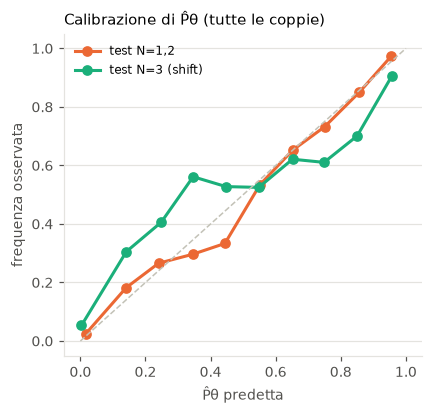

In [8]:
d = np.load('data/pairs.npz', allow_pickle=True)
gbm = pickle.load(open('models/gbm.pkl', 'rb'))
fig, ax = plt.subplots(figsize=(4.2, 3.8))
for X, y, lab, col in ((d['Xte'], d['yte'], 'test N=1,2', COL['B']), (d['Xte3'], d['yte3'], 'test N=3 (shift)', COL['C'])):
    pp = gbm.predict_proba(X)[:, 1]
    bins = np.linspace(0, 1, 11); idx = np.digitize(pp, bins[1:-1])
    xs = [pp[idx == i].mean() for i in range(10) if (idx == i).sum() > 20]
    ys = [y[idx == i].mean() for i in range(10) if (idx == i).sum() > 20]
    ax.plot(xs, ys, marker='o', lw=2, color=col, label=lab)
ax.plot([0, 1], [0, 1], color='#c3c2b7', lw=1, ls='--')
ax.set_xlabel('P̂θ predetta', fontsize=9, color=INK2); ax.set_ylabel('frequenza osservata', fontsize=9, color=INK2)
ax.set_title('Calibrazione di P̂θ (tutte le coppie)', fontsize=10, loc='left'); style_ax(ax); ax.legend(frameon=False, fontsize=8)
coef = pd.Series(M['logreg_coefficients']).head(10)
print('Feature più influenti (coefficienti logreg standardizzati):'); print(coef.round(2).to_string())

## Step 5–6 — Ricerca predittiva (B), distribuzione π e massa residua ρ

**B** è identico ad A tranne l'ordine delle mosse: la differenza B − A misura il guadagno della sola predizione.

**π(a | s)** è definita alla radice:

$$\pi(a\mid s)=\mathrm{softmax}\big(\mathrm{logit}\,\hat P_\theta(s,a)/T\big)$$

con T calibrata sul validation (minimizza la NLL dell'insieme delle mosse vincenti). Significa "credenza del modello che *a* sia la prima mossa del matto".

**Massa residua ρ.** Detta $a^*_t$ la scelta corrente (mossa dimostrata, altrimenti argmax π tra le non confutate):

$$\rho_t=\sum_{a\in U_t}\pi(a\mid s),\qquad U_t=\{\text{mosse radice} \neq a^*_t \text{ né dimostrate né confutate}\}$$

ρ è la probabilità, secondo il modello, che la soluzione stia tra alternative che la ricerca non ha ancora deciso. Si scompone in mosse mai toccate e mosse esplorate solo in parte. Quando una mossa viene confutata, la sua massa si risolve. Se una mossa è dimostrata, la decisione è certa e ρ non rappresenta più un rischio.

In [9]:
b = Board(p['fen']); moves = root_candidates(b, 3)
pp = pred.predict(b, moves, b.side, 5); pi = softmax_logits(pp, params.T)
o = np.argsort(-pi)[:8]
print(pd.DataFrame({'move': [b.uci(moves[i]) for i in o], 'P_hat': pp[o].round(3), 'pi': pi[o].round(3),
                    'key': [b.uci(moves[i]) in p['keys'] for i in o]}).to_string(index=False))

move  P_hat    pi   key
d6b8  0.951 0.715 False
d6e7  0.784 0.135 False
d6c7  0.784 0.135  True
d6f6  0.103 0.004 False
d6b6  0.103 0.004 False
d6f8  0.087 0.004 False
d6d7  0.054 0.002 False
d5e7  0.002 0.000 False


## Step 7 — Regolatore (sistema C, `src/regulator.py`)

$O_t \to R \to U_t$, ricalcolato dopo ogni round di allocazione alla radice.

**Osservabili $O_t$:**

- ρ_t;
- il margine $\tilde\pi_{(1)}-\tilde\pi_{(2)}$, con $\tilde\pi$ = π rinormalizzata sulle mosse non confutate;
- il proxy di errore $\hat R(a)=H_{norm}(\tilde\pi)\cdot w(a)$, con w = 1 per mosse quiete o sacrifici, 0.5 altrimenti.

**Decisioni $U_t$:**

1. **Ampiezza e quote.** Vengono servite le mosse che coprono 1−ε della massa non confutata, con ε più piccolo quando il margine è basso. Ogni mossa riceve una fetta ∝ π(a)(1+λR̂(a)). La fetta minima è 2N+1 espansioni, cioè abbastanza per raggiungere l'orizzonte. Il budget del round raddoppia a ogni round. Le mosse fuori ampiezza sono **rinviate**, non potate.
2. **Stop.** La ricerca si ferma se una mossa è dimostrata, oppure se ρ_t < τ con margine ampio e la mossa scelta è già stata esplorata.

Sotto la radice C usa la stessa ricerca di B. Nei nodi AND il regolatore non pota mai difese: una prova resta una prova.

**Taratura** solo su validation: N=2 val e 200 matti in 3 extra. Si sceglie una sola configurazione con criterio max-min sui due set.
Nota di sviluppo: la prima versione dava fette di 2 espansioni a 12 candidati e non risolveva nulla (C 0.785 < B 0.863 su N=2). La granularità minima 2N+1 ha corretto il problema.

In [10]:
if RECOMPUTE_TUNING:
    run('tune.py', 'n2'); run('tune.py', 'n3', '100,200,400')
for which in ('n2', 'n3'):
    t = pd.DataFrame(json.load(open(f'results/tuning_{which}.json')))
    t['config'] = t.config.astype(str)
    print(f'--- taratura {which} (prime 5 + riferimento B)')
    print(pd.concat([t.head(5), t[t.config == 'B (reference)']]).round(3).to_string(index=False))
print('\nconfigurazione scelta:', {k: v for k, v in vars(params).items()})

--- taratura n2 (prime 5 + riferimento B)
                                                                     config  solve  proven  used  solve@8  solve@16  solve@32
                                                              B (reference)  0.997   0.973  4.87     0.99       1.0       1.0
{'eps0': 0.05, 's0_frac': 0.03125, 'c_min_mult': 2.0, 'k_R': 0, 'lam': 0.0}  0.997   0.973  4.87     0.99       1.0       1.0
{'eps0': 0.05, 's0_frac': 0.03125, 'c_min_mult': 2.0, 'k_R': 2, 'lam': 0.0}  0.997   0.973  4.87     0.99       1.0       1.0
  {'eps0': 0.05, 's0_frac': 0.125, 'c_min_mult': 2.0, 'k_R': 0, 'lam': 0.0}  0.997   0.973  4.87     0.99       1.0       1.0
  {'eps0': 0.05, 's0_frac': 0.125, 'c_min_mult': 2.0, 'k_R': 2, 'lam': 0.0}  0.997   0.973  4.87     0.99       1.0       1.0
                                                              B (reference)  0.997   0.973  4.87     0.99       1.0       1.0
--- taratura n3 (prime 5 + riferimento B)
                                  

## Step 8 — Esperimento: A vs B vs C a parità di espansioni (test)

Test: 400 matti in 1, 400 in 2, 500 in 3. Il budget per puzzle è tarato sulla difficoltà di ciascun N, misurata su validation:
mediana di A per dimostrare ≈ 2.5 espansioni (N=1), 21 (N=2), 400 (N=3).

Metriche:

- **solve**: la prima mossa scelta è vincente, verificato dal solver esaustivo;
- **proven**: la mossa è anche dimostrata entro il budget;
- **used**: espansioni consumate (C può fermarsi prima).

In [11]:
if RECOMPUTE_BENCH:
    run('run_all.py'); run('run_walltime.py'); run('timing.py')
df = load_runs('main'); info = load_info('main')
S = summary(df[df.system.isin(['A', 'B', 'C'])])
S.pivot_table(index=['N', 'budget'], columns='system', values=['solve', 'proven', 'used']).round(3)

proven                solve                  used                
system        A      B      C      A      B      C       A       B       C
N budget                                                                  
1 1       0.000  0.000  0.000  0.588  0.968  0.968   1.000   1.000   1.000
  2       0.588  0.968  0.968  0.825  0.995  0.995   2.000   2.000   2.000
  3       0.825  0.995  0.995  0.928  0.998  0.998   2.412   2.033   2.033
2 4       0.362  0.758  0.758  0.715  0.930  0.930   4.000   4.000   4.000
  8       0.658  0.920  0.920  0.872  0.970  0.970   6.108   4.700   4.700
  16      0.905  0.980  0.982  0.960  1.000  1.000   7.688   5.090   5.082
  32      0.980  0.998  0.995  0.998  1.000  1.000   8.422   5.202   5.178
  64      0.998  0.998  0.995  1.000  1.000  1.000   8.605   5.282   5.258
3 50      0.600  0.782  0.864  0.656  0.794  0.884  28.338  17.586  16.478
  100     0.766  0.842  0.928  0.820  0.858  0.942  44.100  27.270  21.412
  200     0.920  0.924  0.968  0.936  0.934  0.972  58.214  37.970  23.766
  400     0.984  0.984  0.976  0.992  0.988  0.988  65.852  45.366  27.726
  800     0.996  0.998  0.984  0.998  0.998  0.994  68.590  47.492  35.600

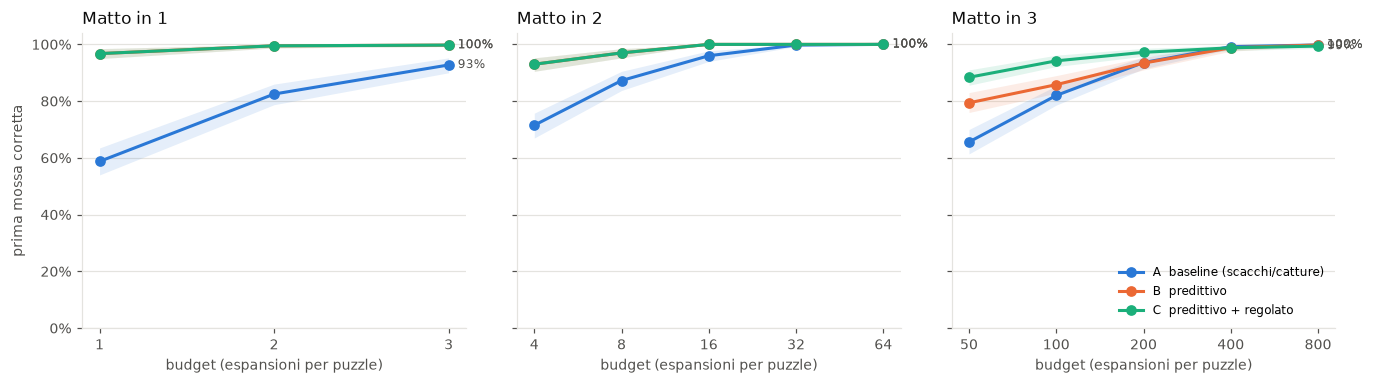

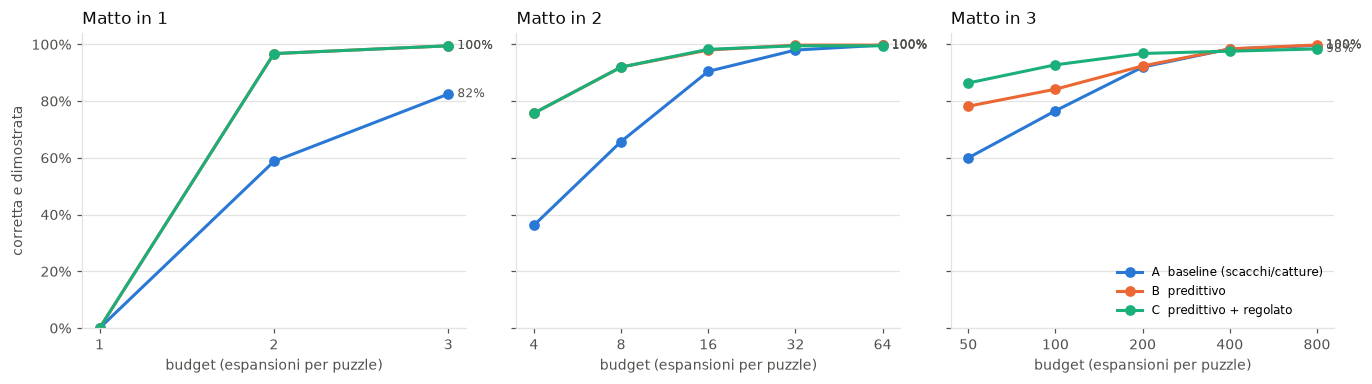

In [12]:
plot_solve_curves(S, metric='solve', fname='solve_vs_budget.png')
plot_solve_curves(S, metric='proven', fname='proven_vs_budget.png');

In [13]:
G = pd.concat([paired_gain(df, 'A', 'B'), paired_gain(df, 'B', 'C')])
print('Guadagno di predizione (B − A) e di regolazione (C − B), test di McNemar esatto sulle coppie discordanti')
G[['N', 'budget', 'comparison', 'gain', 'p_mcnemar']].pivot_table(index=['N', 'budget'], columns='comparison', values=['gain', 'p_mcnemar']).round(4)

Guadagno di predizione (B − A) e di regolazione (C − B), test di McNemar esatto sulle coppie discordanti


gain        p_mcnemar        
comparison   B - A  C - B     B - A   C - B
N budget                                   
1 1         0.3800  0.000    0.0000  1.0000
  2         0.1700  0.000    0.0000  1.0000
  3         0.0700  0.000    0.0000  1.0000
2 4         0.2150  0.000    0.0000  1.0000
  8         0.0975  0.000    0.0000  1.0000
  16        0.0400  0.000    0.0000  1.0000
  32        0.0025  0.000    1.0000  1.0000
  64        0.0000  0.000    1.0000  1.0000
3 50        0.1380  0.090    0.0000  0.0000
  100       0.0380  0.084    0.0699  0.0000
  200      -0.0020  0.038    1.0000  0.0005
  400      -0.0040  0.000    0.7266  1.0000
  800       0.0000 -0.004    1.0000  0.5000

In [14]:
E = efficiency(df)
print('Costo di una risposta certa: mediana delle espansioni sui puzzle dimostrati da tutti e tre i sistemi')
E[E.N >= 2].round(1)

Costo di una risposta certa: mediana delle espansioni sui puzzle dimostrati da tutti e tre i sistemi


,N,budget,both_proven,median_used_A,median_used_B,median_used_C
3,2,4,141,4.000,4.000,4.000
4,2,8,261,4.000,4.000,4.000
5,2,16,362,6.000,4.000,4.000
6,2,32,392,6.000,4.000,4.000
7,2,64,398,6.000,4.000,4.000
8,3,50,263,10.000,6.000,6.000
9,3,100,341,12.000,8.000,8.000
10,3,200,432,16.000,8.000,8.000
11,3,400,479,19.000,8.000,8.000
12,3,800,492,20.000,8.000,8.000


### Stesso confronto a parità di **tempo reale**

Il budget dell'esperimento sono le espansioni. Il calcolo delle feature e del modello (sklearn, Python) però costa 1–2 ms per nodo, contro 0,05 ms di un'espansione.
Qui ogni ricerca gira da sola, con cache vuota, e ad A si danno budget fino a 16× più grandi.

{
"N2@16_A": {
"ms_per_search": 0.5545087333909275,
"ms_per_expansion": 0.06748584990558955
},
"N2@16_B": {
"ms_per_search": 14.352311666577103,
"ms_per_expansion": 2.555307715117585
},
"N2@16_C": {
"ms_per_search": 18.67609558330514,
"ms_per_expansion": 3.3251208753659003
},
"N3@400_A": {
"ms_per_search": 7.234641033331475,
"ms_per_expansion": 0.09676292064197248
},
"N3@400_B": {
"ms_per_search": 97.0113458664855,
"ms_per_expansion": 2.1150729476704684
},
"N3@400_C": {
"ms_per_search": 64.58488165001958,
"ms_per_expansion": 2.3657465805867974
}
}


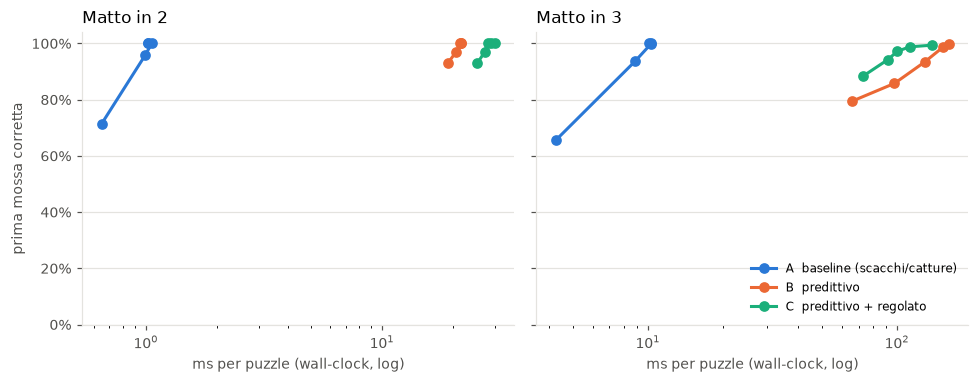

In [15]:
W = load_runs('walltime')
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for ax, n in zip(axes, (2, 3)):
    for s in 'ABC':
        g = W[(W.n == n) & (W.system == s)].groupby('budget').agg(solve=('correct', 'mean'), ms=('time', lambda t: 1000 * t.mean()))
        ax.plot(g.ms, g.solve, marker='o', lw=2, color=COL[s], label=SYSTEM_LABEL[s])
    ax.set_xscale('log'); ax.set_title(f'Matto in {n}', fontsize=11, loc='left')
    ax.set_xlabel('ms per puzzle (wall-clock, log)', fontsize=9, color=INK2); ax.set_ylim(0, 1.04); style_ax(ax)
axes[0].set_ylabel('prima mossa corretta', fontsize=9, color=INK2)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}')); axes[1].legend(frameon=False, fontsize=8, loc='lower right')
fig.tight_layout(); fig.savefig('figures/solve_vs_walltime.png', dpi=150)
print(json.dumps(json.load(open('results/timing.json')), indent=0))

## Step 9 — Ablation

| variante | cosa cambia | domanda di verifica |
|---|---|---|
| `C_flat` | π uniforme (T → ∞) alla radice | distribuzione appiattita |
| `C_noR` | niente R̂ (λ = 0, nessuna ammissione) | rimuovere una sorgente di incertezza |
| `C_admit` | R̂ ammette fino a 2 mosse rinviate | il segnale "needs more thinking" serve? |
| `C_noStop` | niente stop anticipato | residuo forzato a essere risolto |
| `B_noise`, `C_noise` | rumore N(0, 1.5) sui logit, T non ricalibrata | predittore meno accurato e mal calibrato |
| `B_logreg`, `C_logreg` | regressione logistica (più debole ma calibrata) | modello più semplice |
| `B_withn3`, `C_withn3` | modello addestrato anche su matti in 3 | cambia la distribuzione di training |

In [16]:
A = summary(df[df.n >= 2])
order = ['A', 'B', 'C', 'C_flat', 'C_noR', 'C_admit', 'C_noStop', 'B_noise', 'C_noise', 'B_logreg', 'C_logreg', 'B_withn3', 'C_withn3']
tbl = A.pivot_table(index=['N', 'budget'], columns='system', values='solve')[order]
print('solve rate'); print(tbl.round(3).to_string())
print('\nespansioni usate'); print(A.pivot_table(index=['N', 'budget'], columns='system', values='used')[order].round(1).to_string())

solve rate
system        A      B      C  C_flat  C_noR  C_admit  C_noStop  B_noise  C_noise  B_logreg  C_logreg  B_withn3  C_withn3
N budget                                                                                                                 
2 4       0.715  0.930  0.930   0.935  0.930    0.930     0.930    0.892    0.900     0.868     0.868       NaN       NaN
  8       0.872  0.970  0.970   0.965  0.970    0.970     0.970    0.970    0.960     0.942     0.942       NaN       NaN
  16      0.960  1.000  1.000   0.985  1.000    1.000     1.000    0.990    0.990     0.990     0.990       NaN       NaN
  32      0.998  1.000  1.000   0.990  1.000    1.000     1.000    1.000    0.995     0.995     0.995       NaN       NaN
  64      1.000  1.000  1.000   0.990  1.000    1.000     1.000    1.000    1.000     1.000     0.998       NaN       NaN
3 50      0.656  0.794  0.884   0.916  0.884    0.884     0.884    0.742    0.830     0.666     0.808     0.844     0.908
  100     0.8

In [17]:
for a, c in (('B_noise', 'C_noise'), ('B_logreg', 'C_logreg'), ('B_withn3', 'C_withn3'), ('C', 'C_noStop'), ('C', 'C_flat')):
    g = paired_gain(df[df.n == 3], a, c)
    print(f'{c} − {a} (N=3):', ', '.join(f"{r.budget}: {r.gain:+.3f} (p={r.p_mcnemar:.3f})" for r in g.itertuples()))

C_noise − B_noise (N=3): 50: +0.088 (p=0.000), 100: +0.066 (p=0.000), 200: +0.022 (p=0.152), 400: -0.014 (p=0.265), 800: -0.012 (p=0.070)
C_logreg − B_logreg (N=3): 50: +0.142 (p=0.000), 100: +0.134 (p=0.000), 200: +0.074 (p=0.000), 400: +0.028 (p=0.004), 800: -0.006 (p=0.375)
C_withn3 − B_withn3 (N=3): 50: +0.064 (p=0.000), 100: +0.078 (p=0.000), 200: +0.028 (p=0.004), 400: +0.002 (p=1.000), 800: -0.004 (p=0.500)
C_noStop − C (N=3): 50: +0.000 (p=1.000), 100: +0.002 (p=1.000), 200: +0.004 (p=0.500), 400: +0.006 (p=0.250), 800: +0.004 (p=0.500)
C_flat − C (N=3): 50: +0.032 (p=0.004), 100: +0.010 (p=0.442), 200: -0.014 (p=0.143), 400: -0.018 (p=0.022), 800: -0.002 (p=1.000)


## Step 6 bis — ρ come misura di rischio, orizzonte vs frontiera attiva

In [18]:
u = df[(~df.proven) & df.system.isin(['A', 'B', 'C']) & (df.n >= 2)].copy()
u['rho_bin'] = pd.cut(u.rho, [-0.01, 0.05, 0.2, 0.5, 0.8, 1.0])
print('Decisioni NON dimostrate: tasso di errore in funzione di ρ allo stop')
print(u.groupby(['rho_bin'], observed=True).agg(error_rate=('correct', lambda x: 1 - x.mean()), n=('correct', 'size')).round(3).to_string())
F = df[df.system.isin(['A', 'B', 'C']) & (df.n == 3)].groupby(['budget', 'system'])[['fr_expanded', 'fr_horizon', 'fr_active', 'fr_closed', 'fr_deferred']].mean()
print('\nMatto in 3: dimensione media di albero espanso, orizzonte e frontiera attiva allo stop'); print(F.round(1).to_string())

Decisioni NON dimostrate: tasso di errore in funzione di ρ allo stop
               error_rate    n
rho_bin                       
(-0.01, 0.05]       0.206  403
(0.05, 0.2]         0.532  220
(0.2, 0.5]          0.635  296
(0.5, 0.8]          0.887  231
(0.8, 1.0]          0.942  310

Matto in 3: dimensione media di albero espanso, orizzonte e frontiera attiva allo stop
               fr_expanded  fr_horizon  fr_active  fr_closed  fr_deferred
budget system                                                            
50     A              28.3       328.1       26.2      301.9          0.0
       B              17.6       169.2       15.5      153.8          0.0
       C              16.5       151.6       10.8      137.2          3.6
100    A              44.1       516.7       16.4      500.3          0.0
       B              27.3       264.4       11.1      253.3          0.0
       C              21.4       194.2        6.0      186.5          1.8
200    A              58.2       6

## Step 10 — Domanda 16: quando cercare conviene anche se la predizione "non è interessante"

Le mosse chiave **quiete** hanno $\hat P_\theta$ basso (rango mediano 2, $\hat P$ mediano 0.14–0.23). L'euristica "scacchi prima" di A le esplora per ultime.

In [19]:
info['cls'] = np.where(info.sacrifice, 'sacrifice', np.where(info.quiet, 'quiet', 'check/capture'))
print(info.groupby(['n', 'cls']).agg(puzzles=('id', 'size'), pred_top1=('key_rank', lambda r: (r == 1).mean()),
      median_rank=('key_rank', 'median'), median_P_key=('p_key', 'median'), mean_R_key=('R_key', 'mean')).round(3).to_string())
X = df.merge(info[['id', 'cls']], on='id')
for n, b in ((2, 16), (3, 200), (3, 800)):
    g = X[(X.n == n) & (X.budget == b) & X.system.isin(['A', 'B', 'C'])]
    print(f'\nN={n}, budget {b}: solve rate per tipo di mossa chiave')
    print(g.pivot_table(index='cls', columns='system', values='correct').round(3).to_string())

                 puzzles  pred_top1  median_rank  median_P_key  mean_R_key
n cls                                                                     
1 check/capture      180      1.000          1.0         0.951       0.022
  sacrifice          220      0.941          1.0         0.911       0.088
2 check/capture      212      0.967          1.0         0.928       0.027
  quiet                5      0.200          2.0         0.154       0.608
  sacrifice          183      0.836          1.0         0.645       0.127
3 check/capture      179      0.922          1.0         0.833       0.046
  quiet               11      0.182          3.0         0.003       0.333
  sacrifice          310      0.723          1.0         0.575       0.168

N=2, budget 16: solve rate per tipo di mossa chiave
system             A    B    C
cls                           
check/capture  0.976  1.0  1.0
quiet          0.800  1.0  1.0
sacrifice      0.945  1.0  1.0

N=3, budget 200: solve rate per tipo di m

m3_00158 chiave ['d6c7'] | B spende [('d6b8', 106), ('d6e7', 39), ('d6c7', 5)] | C spende [('d6b8', 53), ('d6e7', 28), ('d6c7', 5)]
m3_00400 chiave ['d4f2'] | B spende [('d4f2', 7)] | C spende [('d4f2', 7)]
m3_00163 chiave ['e3h3'] | B spende [('e3h3', 7)] | C spende [('e3h3', 7)]


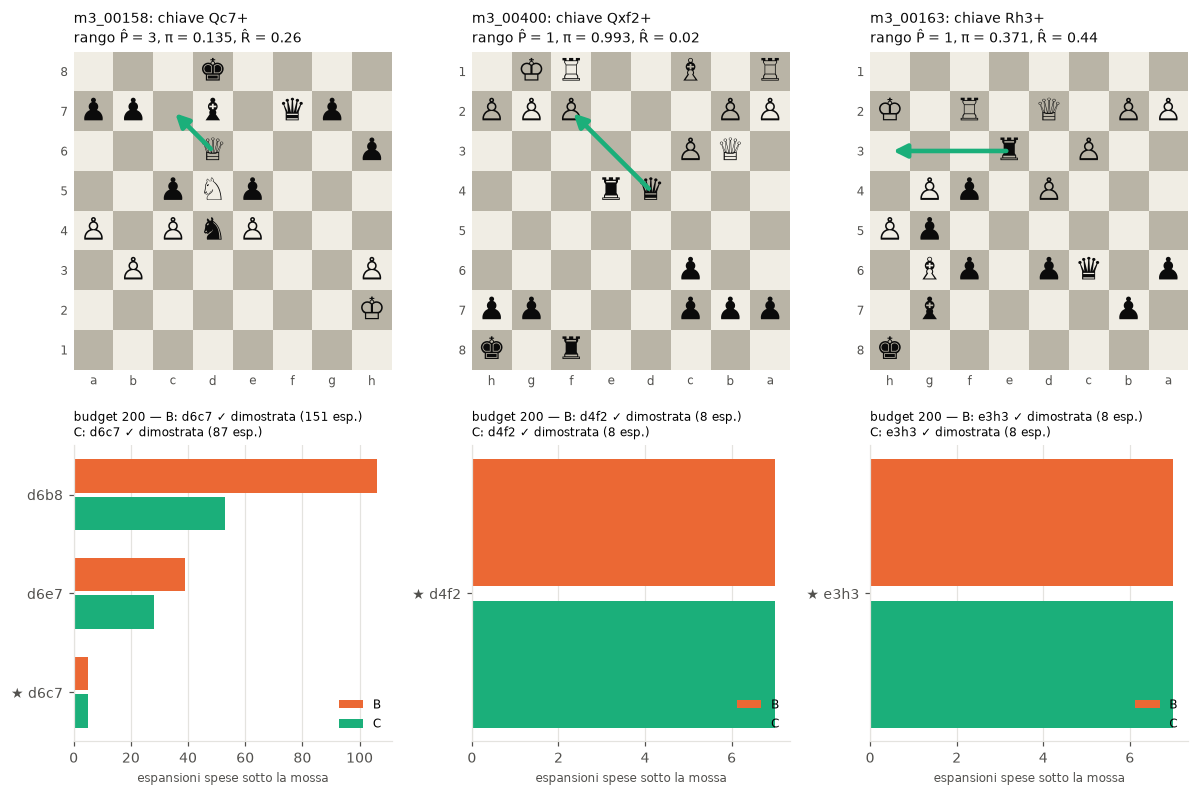

In [20]:
from viz import draw_board, plot_allocation
examples = ['m3_00158', 'm3_00400', 'm3_00163']
fig, axes = plt.subplots(2, 3, figsize=(11, 7.4), gridspec_kw={'height_ratios': [1.25, 1]})
for j, pid in enumerate(examples):
    q = pz[pid]; i = info.set_index('id').loc[pid]
    draw_board(axes[0, j], q['fen'], arrow=q['keys'][0],
               title=f"{pid}: chiave {q['key_san']}" + (f" (vincente anche {q['keys'][1]})" if len(q['keys']) > 1 else "")
                     + f"\nrango P̂ = {i.key_rank}, π = {i.pi_key:.3f}, R̂ = {i.R_key:.2f}")
    al, res = {}, {}
    for name in 'BC':
        pred.clear(); b = Board(q['fen'])
        s = Searcher(ModelPolicy(pred), 200)
        m, pr = s.solve(b, 3) if name == 'B' else solve_regulated(s, b, 3, pred, params)
        al[name] = {b.uci(k): v for k, v in root_allocation(s).items() if v}
        res[name] = f"{b.uci(m)} {'✓' if b.uci(m) in q['keys'] else '✗'}{' dimostrata' if pr else ''} ({s.used} esp.)"
    plot_allocation(axes[1, j], al['B'], al['C'], q['keys'])
    axes[1, j].set_title(f"budget 200 — B: {res['B']}\nC: {res['C']}", fontsize=8, loc='left')
    print(pid, 'chiave', q['keys'], '| B spende', sorted(al['B'].items(), key=lambda x: -x[1])[:4], '| C spende', sorted(al['C'].items(), key=lambda x: -x[1])[:5])
fig.tight_layout(); fig.savefig('figures/q16_examples.png', dpi=150)

## Domanda 13 — errore di predizione e bisogno di ricerca

Sulle radici del test, $r(s,a)=P^*(s,a)-\hat P_\theta(s,a)$, con $P^*$ dato dall'insegnante esaustivo. Due domande:

1. il proxy R̂ individua le coppie con |r| > 0.5?
2. a livello di stato, l'incertezza (entropia di π, oppure 1 − max π) individua le posizioni in cui fermarsi alla predizione, cioè budget zero, è pericoloso?

In [21]:
T = params.T
for nm, X_, y_, t_, p_ in (('N=1,2', d['Xte'], d['yte'], d['tte'], d['pte']), ('N=3', d['Xte3'], d['yte3'], d['tte3'], d['pte3'])):
    res, R = residual_analysis(gbm, T, X_, y_, t_, p_)
    res.pop('auc_lowP_flags_big_error', None)
    print(nm, json.dumps({k: round(v, 3) for k, v in res.items()}))
for n in (2, 3):
    print(f'N={n} stop-danger:', {k: round(v, 3) for k, v in stop_danger(info[info.n == n]).items()})

N=1,2 {"pairs": 14343, "mean_abs_residual": 0.021, "share_big_errors": 0.013, "big_errors_are_false_negatives": 0.401, "auc_Rhat_flags_big_error": 0.816, "auc_Rhat_flags_missed_key": 0.89}
N=3 {"pairs": 16531, "mean_abs_residual": 0.023, "share_big_errors": 0.017, "big_errors_are_false_negatives": 0.557, "auc_Rhat_flags_big_error": 0.673, "auc_Rhat_flags_missed_key": 0.817}
N=2 stop-danger: {'puzzles': 400, 'prediction_only_error': 0.102, 'auc_H_flags_wrong_prediction': 0.89, 'auc_pi_top_flags_wrong_prediction': 0.901}
N=3 stop-danger: {'puzzles': 500, 'prediction_only_error': 0.218, 'auc_H_flags_wrong_prediction': 0.812, 'auc_pi_top_flags_wrong_prediction': 0.818}


## Sintesi
 
- **Predizione (B − A)**: guadagno grande e significativo a ogni budget per N = 1 (da +7 a +38 punti), per N = 2 (da +4 a +21.5 punti) e per N = 3 a budget bassi (+13.8 punti a budget 50). L'accuratezza top-1 del predittore sulle posizioni Lichess raggiunge il 96.8% su N=1, l'89.8% su N=2 e il 78.2% su N=3.
- **Regolazione (C − B)**: nulla sui matti in 1–2, dove B satura rapidamente al 97–100% e il depth-first guidato è già ottimale. Significativa e marcata sui matti in 3 (fuori distribuzione): **+9.0 punti a budget 50** ($p = 6.8\cdot 10^{-13}$), **+8.4 punti a budget 100** ($p = 1.3\cdot 10^{-10}$) e **+3.8 punti a budget 200** ($p = 5.5\cdot 10^{-4}$), riducendo drasticamente le espansioni usate (ad es. da 27.3 a 21.4 a budget 100 e da 38.0 a 23.8 a budget 200). Il beneficio emerge soprattutto quando la chiave non è al primo posto (rango $\ge 2$), dove C supera B del +41.3% a budget 50 e del +38.5% a budget 100.
- La regolazione dipende dalla **calibrazione** di π: con π appiattita (`C_flat`) o logit rumorosi il modello perde efficienza a budget maggiori, mentre con modelli più semplici ma calibrati (logreg) il vantaggio relativo cresce (+14.2 punti a budget 50).
- Il proxy **R̂** riconosce le chiavi sottostimate tra le mosse vincenti ma non aggiunge potere discriminante rispetto alle altre alternative: in ricerca `C_noR` ≈ C (risultato negativo confermato).
- **Tempo reale**: con feature e modello in Python, ogni nodo predetto costa ~2–3 ms per espansione contro ~0.07 ms di A. A parità di tempo reale A con budget maggiori vince grazie alla velocità pura del generatore di mosse.
 
Le risposte alle 16 domande sono in `report.md`.